In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset path
file_path = r"C:\Users\DELL\Downloads\archive (5)\combined_full_cleaned.csv"

# Load dataset
df = pd.read_csv(file_path)

# Display dataset information
print("Dataset Loaded Successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

C:\Users\DELL\AppData\Local\Temp\ipykernel_15592\3583387244.py:10: DtypeWarning: Columns (2: review_title, 5: review_date) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Dataset Loaded Successfully!
Total Rows: 213928
Total Columns: 10


,source,text,review_title,review_rating,number_of_helpful,review_date,perplexity,readability,label,class_name
0,amazon_reviews,This pipe cutter is super convenient because i...,Cut pvc like fruit.,5,4,2020-03-10,40.59,49.50,1,fake
1,amazon_reviews,Got this to cut the pipe behind toilet that wa...,Super easy to use,5,5,2020-03-04,17.57,57.23,1,fake
2,amazon_reviews,Light is very well packaged to protect it duri...,Good quality,5,1,2020-08-14,24.65,54.07,1,fake
3,amazon_reviews,I am using this for my aquarium. The light is ...,geow light,5,0,2020-07-08,32.81,58.76,1,fake
4,amazon_reviews,"To me, simplicity is the most important when i...",Awesome unit.,5,1,2019-12-09,36.64,53.37,1,fake


In [3]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Columns:
['source', 'text', 'review_title', 'review_rating', 'number_of_helpful', 'review_date', 'perplexity', 'readability', 'label', 'class_name']

First 5 Rows:


,source,text,review_title,review_rating,number_of_helpful,review_date,perplexity,readability,label,class_name
0,amazon_reviews,This pipe cutter is super convenient because i...,Cut pvc like fruit.,5,4,2020-03-10,40.59,49.50,1,fake
1,amazon_reviews,Got this to cut the pipe behind toilet that wa...,Super easy to use,5,5,2020-03-04,17.57,57.23,1,fake
2,amazon_reviews,Light is very well packaged to protect it duri...,Good quality,5,1,2020-08-14,24.65,54.07,1,fake
3,amazon_reviews,I am using this for my aquarium. The light is ...,geow light,5,0,2020-07-08,32.81,58.76,1,fake
4,amazon_reviews,"To me, simplicity is the most important when i...",Awesome unit.,5,1,2019-12-09,36.64,53.37,1,fake



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 213928 entries, 0 to 213927
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   source             213928 non-null  str    
 1   text               213928 non-null  str    
 2   review_title       32236 non-null   str    
 3   review_rating      213928 non-null  int64  
 4   number_of_helpful  213928 non-null  int64  
 5   review_date        32496 non-null   str    
 6   perplexity         213928 non-null  float64
 7   readability        213928 non-null  float64
 8   label              213928 non-null  int64  
 9   class_name         213928 non-null  str    
dtypes: float64(2), int64(3), str(5)
memory usage: 395.8 MB


In [4]:
# Check review categories
print("Class Name Counts:")
print(df["class_name"].value_counts(dropna=False))

print("\nNumerical Label Counts:")
print(df["label"].value_counts(dropna=False))

print("\nSource Counts:")
print(df["source"].value_counts())

Class Name Counts:
class_name
bot        181432
fake        22109
genuine     10387
Name: count, dtype: int64

Numerical Label Counts:
label
2    181432
1     22109
0     10387
Name: count, dtype: int64

Source Counts:
source
ai_human          181432
amazon_reviews     32496
Name: count, dtype: int64


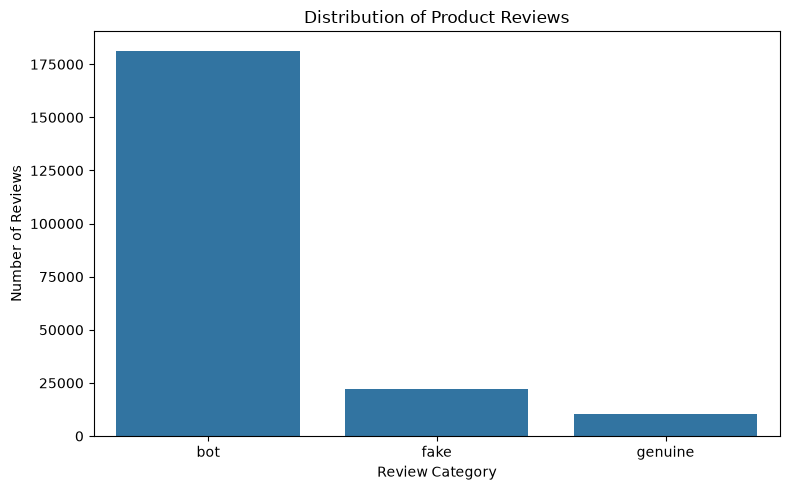

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count reviews in each category
class_counts = df["class_name"].value_counts()

# Bar graph
plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Distribution of Product Reviews")
plt.xlabel("Review Category")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

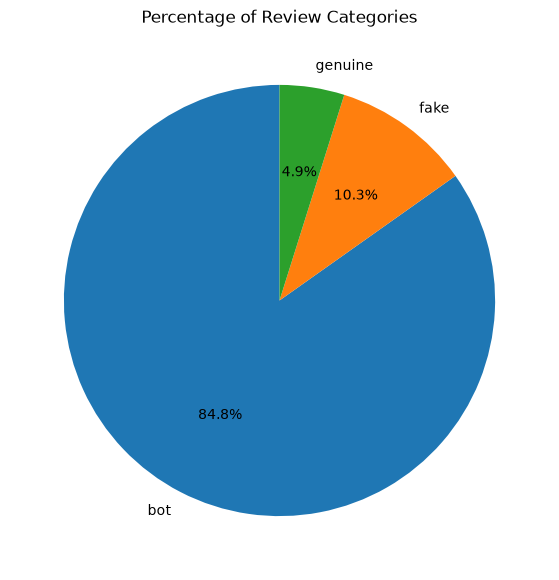

In [6]:
class_percentage = (
    df["class_name"]
    .value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage.values,
    labels=class_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Review Categories")
plt.show()

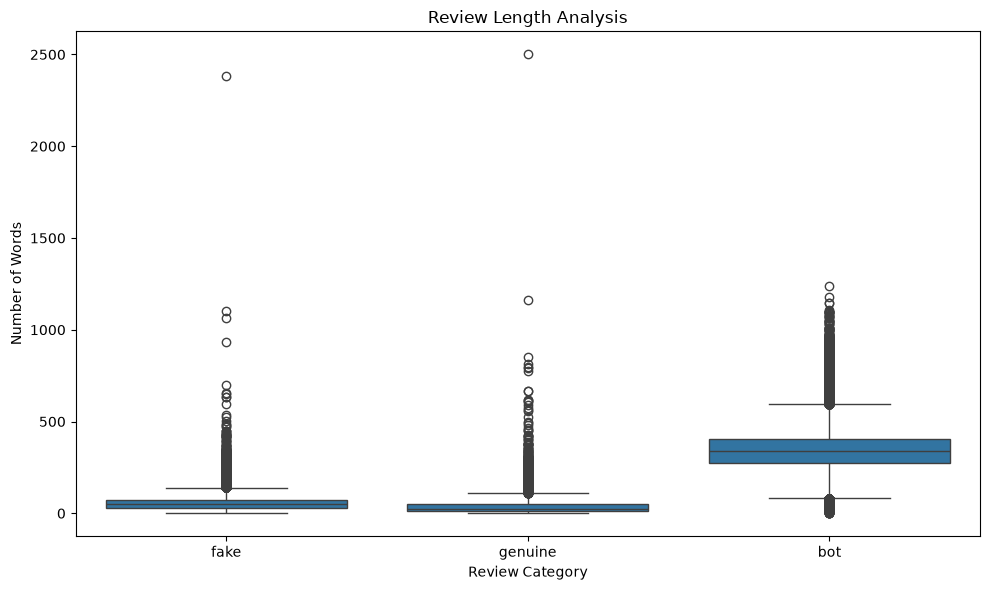

In [7]:
# Calculate number of words in each review
df["review_length"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="class_name",
    y="review_length"
)

plt.title("Review Length Analysis")
plt.xlabel("Review Category")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

In [8]:
summary = df.groupby("class_name").agg(
    total_reviews=("text", "count"),
    average_rating=("review_rating", "mean"),
    average_review_length=("review_length", "mean"),
    average_helpful_votes=("number_of_helpful", "mean")
)

display(summary.round(2))

,total_reviews,average_rating,average_review_length,average_helpful_votes
class_name,,,,
bot,181432,-1.00,344.41,0.00
fake,22109,4.82,59.59,3.04
genuine,10387,4.34,41.80,1.15


Average Rating:
class_name
bot       -1.00
fake       4.82
genuine    4.34
Name: review_rating, dtype: float64


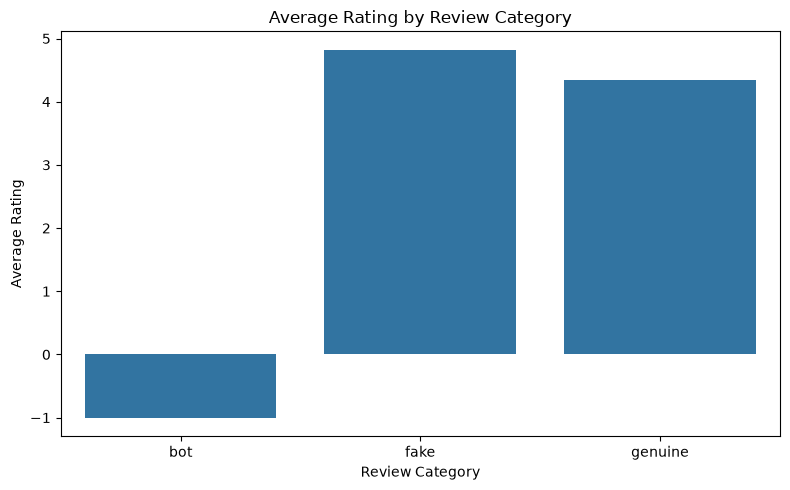

In [9]:
# Rating comparison
rating_data = df.groupby(
    "class_name"
)["review_rating"].mean()

print("Average Rating:")
print(rating_data.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_data.index,
    y=rating_data.values
)

plt.title("Average Rating by Review Category")
plt.xlabel("Review Category")
plt.ylabel("Average Rating")

plt.tight_layout()
plt.show()

Average Helpful Votes:
class_name
bot        0.00
fake       3.04
genuine    1.15
Name: number_of_helpful, dtype: float64


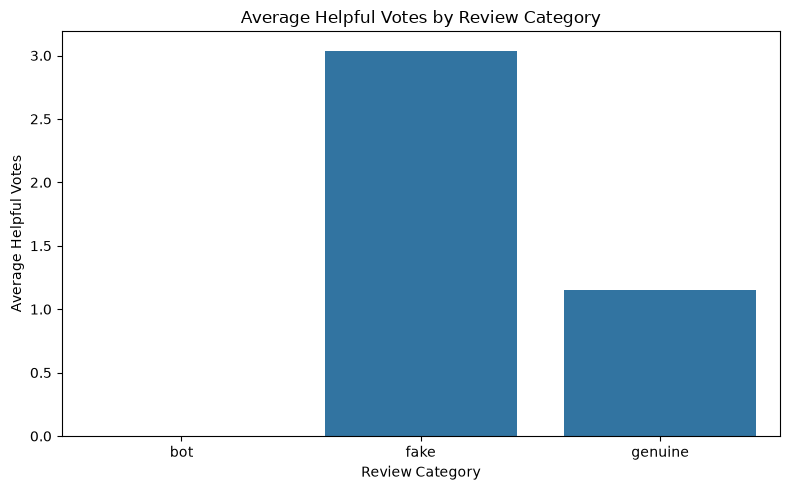

In [10]:
helpful_data = df.groupby(
    "class_name"
)["number_of_helpful"].mean()

print("Average Helpful Votes:")
print(helpful_data.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=helpful_data.index,
    y=helpful_data.values
)

plt.title("Average Helpful Votes by Review Category")
plt.xlabel("Review Category")
plt.ylabel("Average Helpful Votes")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Remove missing review text
data = df.dropna(subset=["text", "class_name"]).copy()

# Review text and target labels
X = data["text"].astype(str)
y = data["class_name"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train classification model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train_tfidf, y_train)

# Predict test reviews
y_pred = model.predict(X_test_tfidf)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.54 %

Classification Report:
              precision    recall  f1-score   support

         bot       1.00      1.00      1.00     36287
        fake       0.82      0.73      0.77      4422
     genuine       0.54      0.68      0.60      2077

    accuracy                           0.96     42786
   macro avg       0.79      0.80      0.79     42786
weighted avg       0.96      0.96      0.96     42786



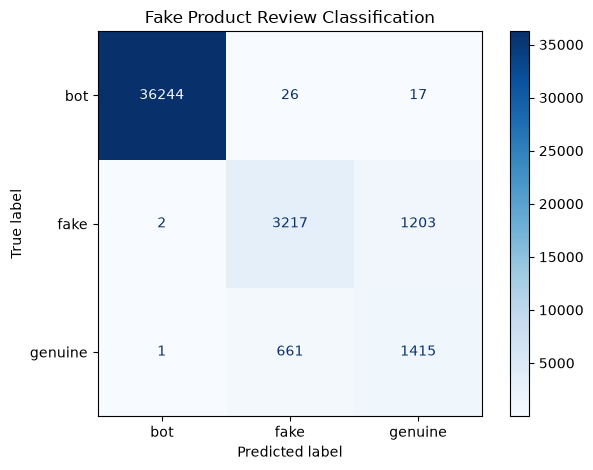

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Fake Product Review Classification")
plt.tight_layout()
plt.show()

In [16]:
# Enter a new product review
new_review = input("Enter Product Review: ")

# Convert review into TF-IDF features
new_review_tfidf = tfidf.transform([new_review])

# Predict category
prediction = model.predict(new_review_tfidf)

print("\nReview Analysis Result:")
print("Predicted Category:", prediction[0])

Enter Product Review:  Excellent product! I love it. Highly recommended.



Review Analysis Result:
Predicted Category: genuine


In [17]:
import joblib

# Save trained model and TF-IDF vectorizer
joblib.dump(model, "fake_review_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and Vectorizer Saved Successfully!")

Model and Vectorizer Saved Successfully!


In [18]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [19]:
import os

print(os.getcwd())

C:\Users\DELL


In [20]:
import os

print(os.listdir(r"C:\Users\DELL"))

['.anaconda', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.docker', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.python_history', '.spyder-py3', '.streamlit', '.VirtualBox', '.vscode', '.vscode-shared', 'AI_Waste_Project', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'cvprac7.ipynb', 'Desktop', 'Documents', 'Downloads', 'fake_review_dashboard.py', 'fake_review_model.pkl', 'Favorites', 'IntelGraphicsProfiles', 'iris_csv.txt', 'jupyter_runtime', 'Links', 'Local Settings', 'ml1.ipynb', 'ml7.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf.cnpf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.T

In [23]:
import joblib

accuracy = 0.9554

joblib.dump(accuracy, r"C:\Users\DELL\model_accuracy.pkl")

print("Model Accuracy Saved: 95.54%")

Model Accuracy Saved: 95.54%


In [25]:
print("X_train:", type(X_train))
print("X_test:", type(X_test))
print("y_train:", type(y_train))
print("y_test:", type(y_test))

X_train: <class 'pandas.Series'>
X_test: <class 'pandas.Series'>
y_train: <class 'pandas.Series'>
y_test: <class 'pandas.Series'>


In [27]:
import pandas as pd
import joblib
from sklearn.metrics import confusion_matrix, accuracy_score

# Convert test reviews into TF-IDF
X_test_tfidf = tfidf.transform(X_test.astype(str))

# Predict
y_pred = model.predict(X_test_tfidf)

# Convert actual and predicted labels to same type
y_true = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()

# Get all classes
classes = sorted(set(y_true) | set(y_pred))

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

# Calculate actual accuracy
accuracy = accuracy_score(y_true, y_pred)

# Save evaluation files
joblib.dump(accuracy, r"C:\Users\DELL\model_accuracy.pkl")
joblib.dump(cm, r"C:\Users\DELL\confusion_matrix.pkl")
joblib.dump(classes, r"C:\Users\DELL\confusion_classes.pkl")

# Display results
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:")
print(cm)
print("\nClass Labels:")
print(classes)

print("\nEvaluation files saved successfully!")

Model Accuracy: 95.54 %

Confusion Matrix:
[[36244    26    17]
 [    2  3217  1203]
 [    1   661  1415]]

Class Labels:
['bot', 'fake', 'genuine']

Evaluation files saved successfully!
